<a href="https://colab.research.google.com/github/nr868848-stack/E-commerce-Sales-Analysis/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# pandas and numpy to work with data
# matplotlib and seaborn to create charts
# scikit-learn to prepare data, train models, and evaluate predictions

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme()

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# The target column is Churn:
# Yes = the customer left
# No = the customer stayed
# The original public dataset contains customer information such as tenure, contract type, monthly charges, and services.

DATA_URL = "https://raw.githubusercontent.com/IBM/Customer-Churn-Data/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"
used_sample_data = False

try:
    df = pd.read_csv(DATA_URL)
    print("Public dataset loaded successfully.")
except Exception as error:
    print("Could not download the public dataset:", error)
    print("Creating a practice dataset instead. Results from this fallback are only for learning.")
    used_sample_data = True
    rng = np.random.default_rng(RANDOM_STATE)
    n = 1200
    tenure = rng.integers(0, 73, n)
    monthly_charges = rng.normal(70, 20, n).clip(18, 120).round(2)
    contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20])
    internet = rng.choice(["DSL", "Fiber optic", "No"], n, p=[0.35, 0.45, 0.20])
    payment = rng.choice(["Electronic check", "Mailed check", "Bank transfer", "Credit card"], n)
    senior = rng.choice([0, 1], n, p=[0.84, 0.16])

    # Generate practice labels from a transparent probability rule with random noise.
    logit = (
        1.2
        + (contract == "Month-to-month") * 1.0
        - (contract == "Two year") * 1.1
        - tenure * 0.045
        + (internet == "Fiber optic") * 0.35
        + (payment == "Electronic check") * 0.45
        + (monthly_charges > 85) * 0.25
        + senior * 0.2
    )
    probability = 1 / (1 + np.exp(-logit))
    churn = np.where(rng.random(n) < probability, "Yes", "No")

    df = pd.DataFrame({
        "customerID": [f"SAMPLE{i:05d}" for i in range(n)],
        "gender": rng.choice(["Female", "Male"], n),
        "SeniorCitizen": senior,
        "Partner": rng.choice(["Yes", "No"], n),
        "Dependents": rng.choice(["Yes", "No"], n),
        "tenure": tenure,
        "PhoneService": rng.choice(["Yes", "No"], n),
        "InternetService": internet,
        "Contract": contract,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": (tenure * monthly_charges).round(2).astype(str),
        "Churn": churn
    })

print("Dataset shape:", df.shape)
display(df.head())

Could not download the public dataset: HTTP Error 404: Not Found
Creating a practice dataset instead. Results from this fallback are only for learning.
Dataset shape: (1200, 13)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,SAMPLE00000,Female,0,No,No,6,No,Fiber optic,Month-to-month,Bank transfer,94.96,569.76,Yes
1,SAMPLE00001,Male,0,Yes,No,56,No,Fiber optic,One year,Mailed check,64.95,3637.2,No
2,SAMPLE00002,Male,0,Yes,No,47,Yes,DSL,One year,Mailed check,77.27,3631.69,No
3,SAMPLE00003,Female,0,Yes,No,32,Yes,DSL,Month-to-month,Electronic check,21.80,697.6,No
4,SAMPLE00004,Male,0,No,Yes,31,No,DSL,Month-to-month,Credit card,46.87,1452.97,Yes


In [ ]:
# Check the number of rows and columns, data types, summary statistics, and missing values before analysis.
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nData types and non-null counts:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nMissing values per column:")
missing_summary = df.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0])

Rows: 1200
Columns: 13

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customerID       1200 non-null   object 
 1   gender           1200 non-null   object 
 2   SeniorCitizen    1200 non-null   int64  
 3   Partner          1200 non-null   object 
 4   Dependents       1200 non-null   object 
 5   tenure           1200 non-null   int64  
 6   PhoneService     1200 non-null   object 
 7   InternetService  1200 non-null   object 
 8   Contract         1200 non-null   object 
 9   PaymentMethod    1200 non-null   object 
 10  MonthlyCharges   1200 non-null   float64
 11  TotalCharges     1200 non-null   object 
 12  Churn            1200 non-null   object 
dtypes: float64(1), int64(2), object(10)
memory usage: 122.0+ KB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,1200,1200,SAMPLE01183,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1200,2,Male,613,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,1200.0,NaN,NaN,NaN,0.141667,0.348853,0.0,0.0,0.0,0.0,1.0
Partner,1200,2,No,608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,1200,2,Yes,601,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,1200.0,NaN,NaN,NaN,36.304167,20.994816,0.0,18.0,36.0,55.0,72.0
PhoneService,1200,2,Yes,623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,1200,3,Fiber optic,532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract,1200,3,Month-to-month,674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,1200,4,Mailed check,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


,0


In [ ]:
# Clean the dataset
# For the standard Telco dataset, TotalCharges may be stored as text and may contain blank values.
# Convert it to numeric and handle missing values later inside the machine-learning pipeline.
# We also remove duplicate rows and drop customerID, which is an identifier rather than a useful predictive feature.

df = df.copy()
df.columns = df.columns.str.strip()

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

before_duplicates = len(df)
df = df.drop_duplicates()
print("Duplicate rows removed:", before_duplicates - len(df))

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].astype(str).str.strip()
df = df[df["Churn"].isin(["Yes", "No"])].copy()

print("Cleaned dataset shape:", df.shape)
print("\nTarget counts:")
display(df["Churn"].value_counts(dropna=False))

Duplicate rows removed: 0
Cleaned dataset shape: (1200, 12)

Target counts:


,count
Churn,
Yes,668
No,532


Overall churn rate: 55.67%


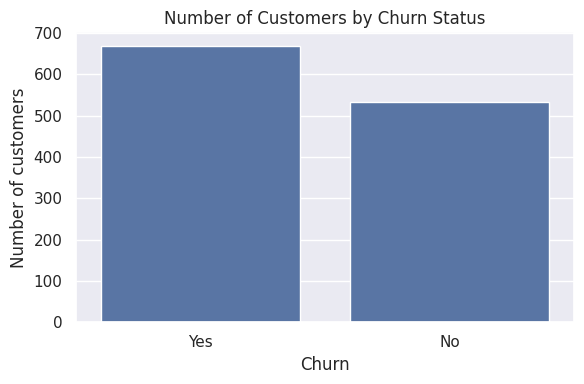

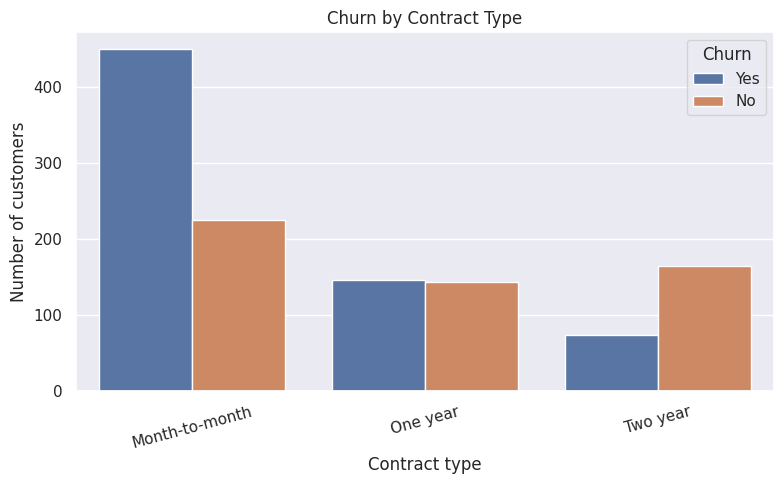

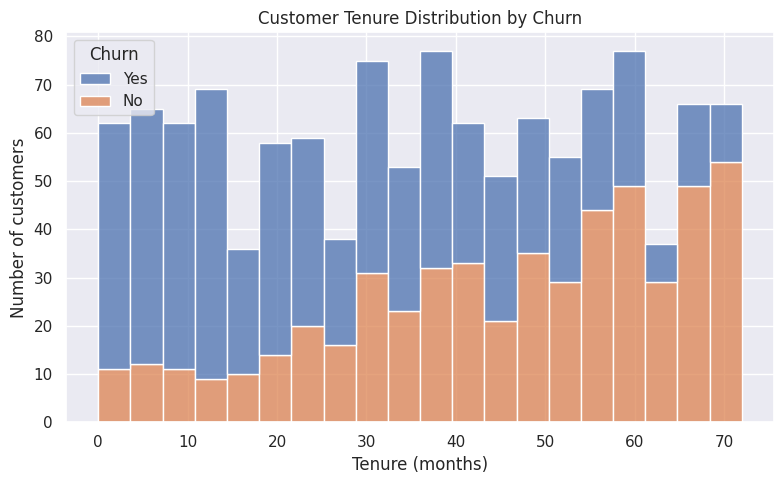

Churn,No,Yes
SeniorCitizen,0.14,0.14
tenure,45.79,28.75
MonthlyCharges,68.35,69.56
TotalCharges,3139.53,2008.82


In [ ]:
# Overall churn rate
churn_counts = df["Churn"].value_counts()
churn_rate = (df["Churn"].eq("Yes").mean() * 100)
print(f"Overall churn rate: {churn_rate:.2f}%")

# Plot Churn Status
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Number of Customers by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Churn by Contract Type
if "Contract" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="Contract", hue="Churn")
    plt.title("Churn by Contract Type")
    plt.xlabel("Contract type")
    plt.ylabel("Number of customers")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

# Customer Tenure Distribution by Churn
if "tenure" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x="tenure", hue="Churn", bins=20, multiple="stack")
    plt.title("Customer Tenure Distribution by Churn")
    plt.xlabel("Tenure (months)")
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

# Numeric features averages grouped by Churn
numeric_cols_for_eda = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols_for_eda:
    display(df.groupby("Churn")[numeric_cols_for_eda].mean().round(2).T)

In [ ]:
# X contains the information used to make predictions. y contains the outcome we want to predict.
# We split the data before training so that the test set remains separate from model fitting.
# stratify=y helps preserve the churn ratio in both sets.

# Define features and target (mapping Churn 'Yes'/'No' to 1/0)
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Data successfully split:")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Data successfully split:
X_train shape: (960, 11), y_train shape: (960,)
X_test shape: (240, 11), y_test shape: (240,)
